# 駆動振幅の較正前後の χ 行列

保存済みの QPT 結果を読み込み、矩形 MS ゲートの駆動振幅を較正する前と後の
**実部・虚部・絶対値**を並べて表示します。既定値は $\bar n=4$ です。
上からすべてのセルを実行すれば表示でき、時間発展や較正の再計算は行いません。

表示対象は既存の研究ノートと同じ **post-gate 誤差チャネル**です。

$$\mathcal N_{\rm post}=\mathcal S_{\rm noisy}\mathcal S_{\rm ideal}^{-1},
\qquad \mathcal N_{\rm post}(\rho)=\sum_{P,Q}\chi_{P,Q}P\rho Q^\dagger.$$

2量子ビット Pauli 基底で $\mathrm{Tr}\,\chi=1$ とした保存行列をそのまま使います。
理想ゲートでは $\chi_{II,II}=1$ です。CPTP 射影や Pauli twirling は行わず、
複素数の非対角要素も保持します。各 $\bar n$ で独立に振幅較正した結果を比較します。

In [6]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# 変更するのは主にここです。None にすると保存済みの全条件を表示します。
NBAR_VALUES = [0.01, 4.0, 10.0, 20.0]
SHOW_NUMERIC_MATRICES = False  # True: 完全な 16 x 16 複素行列も表で表示
SAVE_OUTPUTS = True           # 図 PNG・行列 NPZ・要約 CSV を保存

def find_project_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / "chi_error_nbar_workflow.py").is_file():
            return candidate
    raise FileNotFoundError("このノートブックを MS_gate_Hirai 内で実行してください。")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "results" / "chi_error_element_fit"
CALIBRATION_DIR = (
    DATA_DIR / "advanced_publication_validation" / "hxx_drive_amplitude_calibration"
)
SUMMARY_PATH = CALIBRATION_DIR / "hxx_drive_calibration_final_summary.csv"
MANIFEST_PATH = DATA_DIR / "publication_reproducibility_manifest.json"
OUTPUT_DIR = PROJECT_ROOT / "results" / "drive_amplitude_chi_before_after"

plt.rcParams.update({"font.size": 10, "figure.dpi": 110})
print(f"Project: {PROJECT_ROOT}")

Project: /Users/hirainoa/Desktop/量子/project/Moon_shot__高橋PJ/MS_gate_Hirai


## データの選択と読み込み

較正前は `exact_full_chi`、較正後は `hxx_drive_calibration_final_summary.csv` が指す
最終フィードバックの QPT キャッシュから読み込みます。利用できない $\bar n$ は
エラーとして知らせ、別の温度へ自動的に置き換えません。

$A$ は既存シミュレータの振幅パラメータで、$A/A_0$ が較正による倍率です。
表の χ 要素と診断値は、以下に表示する行列から直接計算します。

In [7]:
manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
if manifest["error_channel_convention"] != "undo_before_actual":
    raise ValueError("post-gate 誤差チャネルと異なる規約のデータです。")
pauli_labels = list(manifest["pauli_basis_order"])
expected_labels = [p + q for p in "IXYZ" for q in "IXYZ"]
if pauli_labels != expected_labels:
    raise ValueError("想定と異なる Pauli 基底順序です。")
ii_index, xx_index = pauli_labels.index("II"), pauli_labels.index("XX")

calibration = pd.read_csv(SUMMARY_PATH)
calibration = (
    calibration.sort_values(["n_bar", "iteration"])
    .drop_duplicates("n_bar", keep="last").reset_index(drop=True)
)
available_nbars = calibration["n_bar"].to_numpy(float)
requested_nbars = available_nbars if NBAR_VALUES is None else np.asarray(NBAR_VALUES, dtype=float)
if requested_nbars.ndim != 1 or not len(requested_nbars):
    raise ValueError("NBAR_VALUES に1つ以上の温度をリストで指定してください。")
selected_rows = []
for requested in dict.fromkeys(requested_nbars.tolist()):
    matches = calibration.loc[np.isclose(available_nbars, requested, rtol=0, atol=1e-10)]
    if len(matches) != 1:
        raise ValueError(f"n_bar={requested:g} は未保存です。候補: {available_nbars.tolist()}")
    selected_rows.append(matches.iloc[0])

def load_chi(path, n_bar):
    if not path.is_file():
        raise FileNotFoundError(f"QPT キャッシュがありません: {path}")
    with np.load(path, allow_pickle=False) as payload:
        chi = np.asarray(payload["chi_trace_normalized"], dtype=complex).copy()
        metadata = json.loads(str(payload["metadata_json"].item()))
        stored_nbar = float(payload["n_bar"].item())
        if "pauli_labels" in payload and payload["pauli_labels"].tolist() != pauli_labels:
            raise ValueError(f"Pauli 基底順序が一致しません: {path}")
    if not np.isclose(stored_nbar, n_bar, rtol=0, atol=1e-10):
        raise ValueError(f"キャッシュの温度が一致しません: {path}")
    if chi.shape != (16, 16) or not np.all(np.isfinite(chi)):
        raise ValueError(f"有限な 16 x 16 行列ではありません: {path}")
    if not np.isclose(np.trace(chi), 1.0, rtol=0, atol=1e-9):
        raise ValueError(f"trace-normalized な χ ではありません: {path}")
    if not np.allclose(chi, chi.conj().T, rtol=0, atol=1e-9):
        raise ValueError(f"χ の Hermiticity を確認してください: {path}")
    return chi, metadata

comparisons, records, source_records = {}, [], []
for row in selected_rows:
    n_bar = float(row["n_bar"])
    stem = str(n_bar).replace(".", "p")
    before_path = DATA_DIR / "exact_full_chi" / f"error_chi_nbar_{stem}.npz"
    # CSV に記録された古い絶対パスを使わず、現在のプロジェクト内から解決する。
    after_path = CALIBRATION_DIR / "qpt_cache" / Path(row["cache_path"]).name
    chi_before, before_metadata = load_chi(before_path, n_bar)
    chi_after, after_metadata = load_chi(after_path, n_bar)
    for key in ("A_factor", "A_calibrated", "iteration"):
        if not np.isclose(float(after_metadata[key]), float(row[key]), rtol=1e-10, atol=1e-12):
            raise ValueError(f"較正 summary とキャッシュの {key} が一致しません。")
    comparisons[n_bar] = {"before": chi_before, "after": chi_after}

    for condition, chi, metadata, path, amplitude, factor, iteration in [
        ("before", chi_before, before_metadata, before_path, after_metadata["A_baseline"], 1.0, 0),
        ("after", chi_after, after_metadata, after_path, after_metadata["A_calibrated"], after_metadata["A_factor"], int(row["iteration"])),
    ]:
        records.append({
            "n_bar": n_bar, "condition": condition,
            "A": amplitude, "A_over_A0": factor, "iteration": iteration,
            "phonon_dim": int(metadata["phonon_dim"]),
            "Re chi[II,II]": chi[ii_index, ii_index].real,
            "Re chi[II,XX]": chi[ii_index, xx_index].real,
            "Im chi[II,XX]": chi[ii_index, xx_index].imag,
            "Re chi[XX,XX]": chi[xx_index, xx_index].real,
            "Re trace(chi)": np.trace(chi).real,
            "Hermiticity error": np.linalg.norm(chi - chi.conj().T),
            "min eigenvalue(chi)": np.linalg.eigvalsh((chi + chi.conj().T) / 2).min(),
        })
        source_records.append({
            "n_bar": n_bar, "condition": condition,
            "source": str(path.relative_to(PROJECT_ROOT)),
        })

summary = pd.DataFrame(records)
sources = pd.DataFrame(source_records)
print("Available n_bar:", available_nbars.tolist())
print("Pauli basis:", ", ".join(pauli_labels))
display(summary.style.format({
    "Hermiticity error": "{:.3e}", "min eigenvalue(chi)": "{:.3e}",
}, precision=6))
# 各 source は下の保存セルでも記録する。
display(sources)

Available n_bar: [0.01, 1.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 16.0, 20.0]
Pauli basis: II, IX, IY, IZ, XI, XX, XY, XZ, YI, YX, YY, YZ, ZI, ZX, ZY, ZZ


,n_bar,condition,A,A_over_A0,iteration,phonon_dim,"Re chi[II,II]","Re chi[II,XX]","Im chi[II,XX]","Re chi[XX,XX]",Re trace(chi),Hermiticity error,min eigenvalue(chi)
0,0.010000,before,0.125000,1.000000,0,20,0.997567,-0.000524,0.013702,0.000353,1.000000,8.227e-16,3.678e-08
1,0.010000,after,0.126108,1.008861,1,20,0.997727,-0.000535,0.000102,0.000170,1.000000,6.089e-16,3.407e-08
2,4.000000,before,0.125000,1.000000,0,67,0.984649,-0.002425,0.071410,0.009469,1.000000,3.307e-16,3.878e-08
3,4.000000,after,0.131222,1.049773,1,67,0.988293,-0.002761,0.000427,0.005153,1.000000,3.090e-16,-4.299e-10
4,10.000000,before,0.125000,1.000000,0,170,0.949648,-0.004553,0.143099,0.040214,1.000000,2.455e-16,-6.773e-08
5,10.000000,after,0.139241,1.113932,1,171,0.959581,-0.006056,-0.000814,0.027274,1.000000,2.680e-16,1.045e-08
6,20.000000,before,0.125000,1.000000,0,354,0.876838,-0.006767,0.225149,0.108596,1.000000,2.274e-16,-1.770e-07
7,20.000000,after,0.151988,1.215906,2,356,0.881956,-0.011242,0.000948,0.094528,1.000000,2.680e-16,-2.223e-07


,n_bar,condition,source
0,0.01,before,results/chi_error_element_fit/exact_full_chi/e...
1,0.01,after,results/chi_error_element_fit/advanced_publica...
2,4.00,before,results/chi_error_element_fit/exact_full_chi/e...
3,4.00,after,results/chi_error_element_fit/advanced_publica...
4,10.00,before,results/chi_error_element_fit/exact_full_chi/e...
5,10.00,after,results/chi_error_element_fit/advanced_publica...
6,20.00,before,results/chi_error_element_fit/exact_full_chi/e...
7,20.00,after,results/chi_error_element_fit/advanced_publica...


## 較正前後の全行列

**上段が較正前、下段が較正後**です。左から実部、虚部、絶対値を表示します。
同じ列の2枚は共通の色スケールで、実部・虚部の色はゼロを中心にしています。
縦軸が行 $P$、横軸が列 $Q$ です。この図は $\chi_{II,II}$ を含む全要素を表示します。

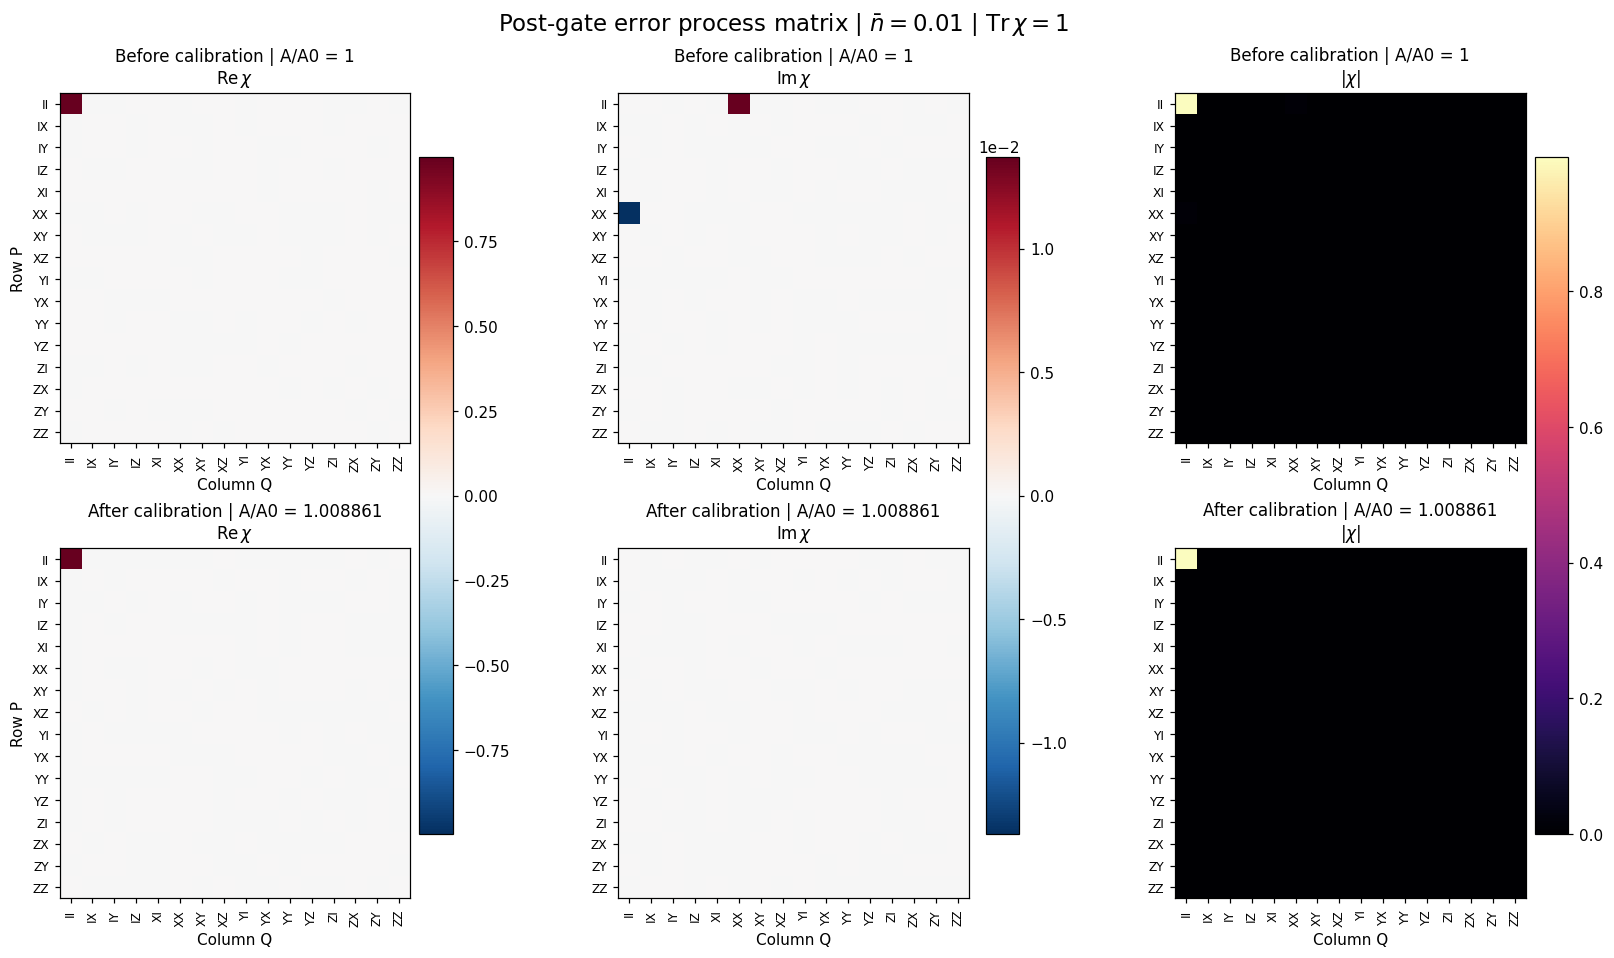

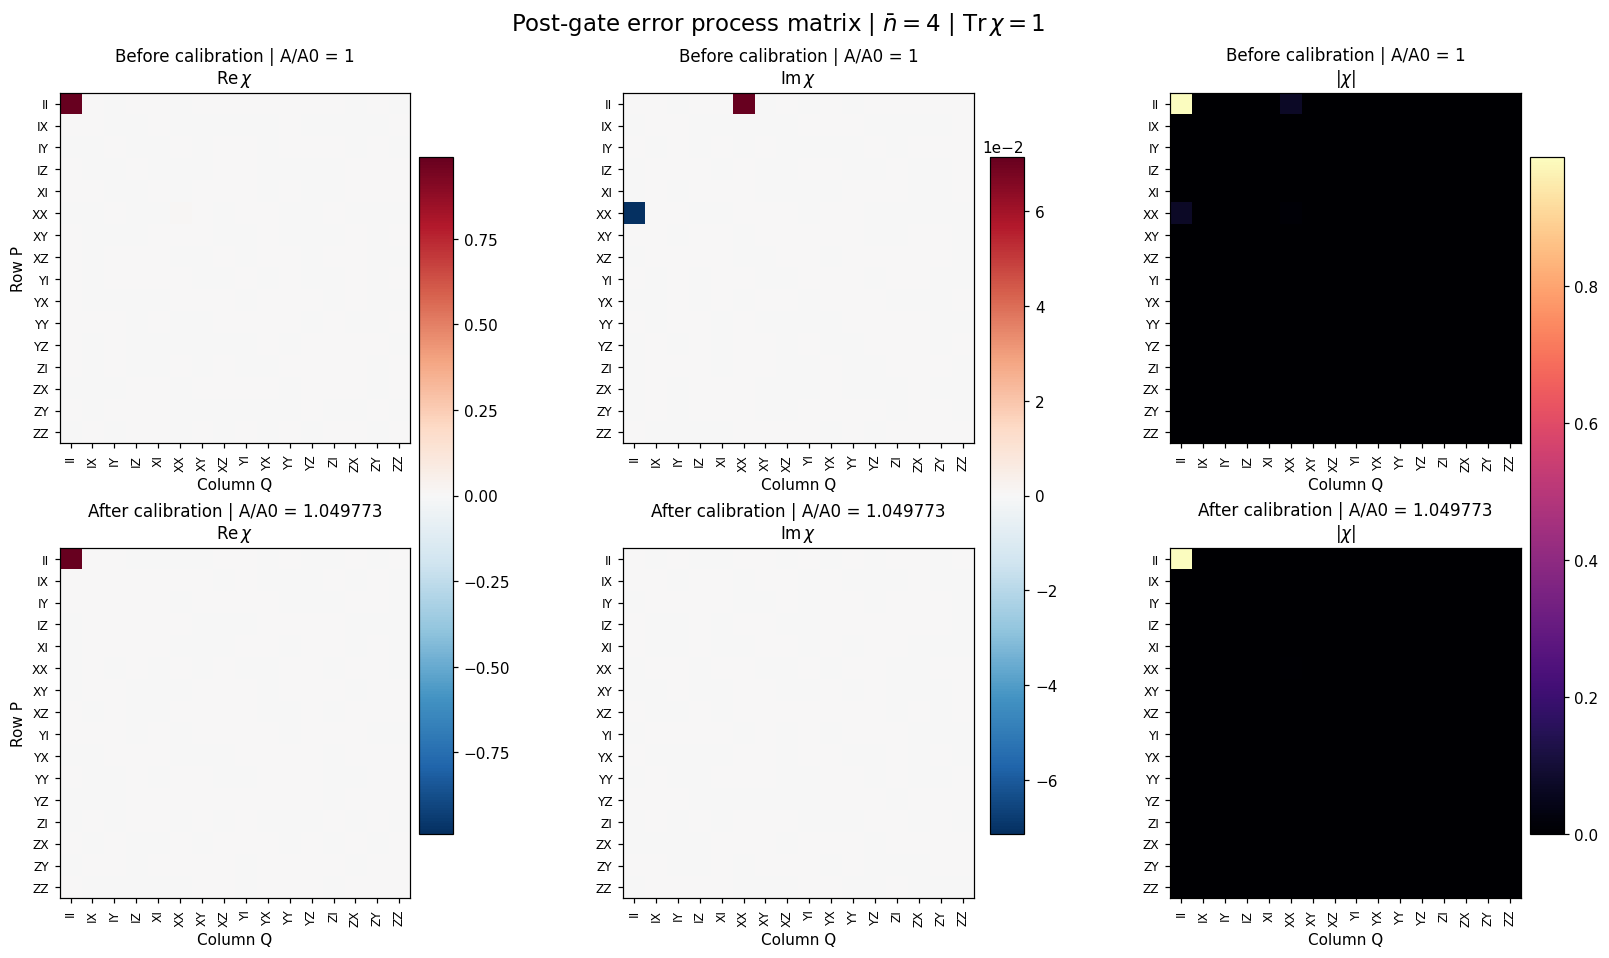

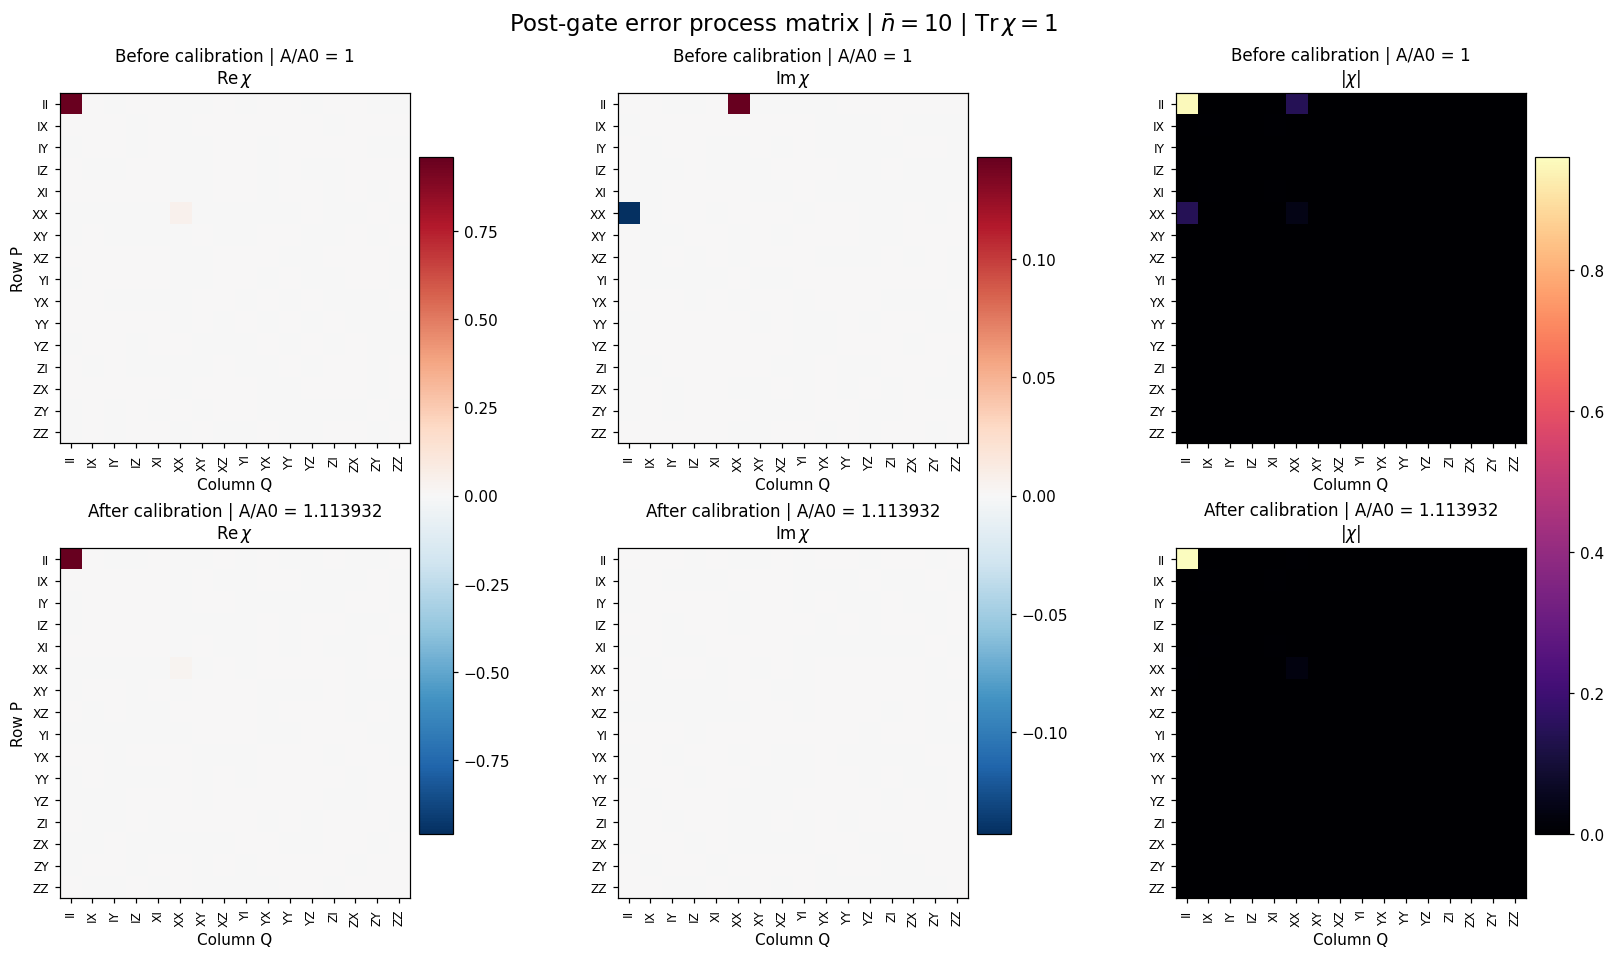

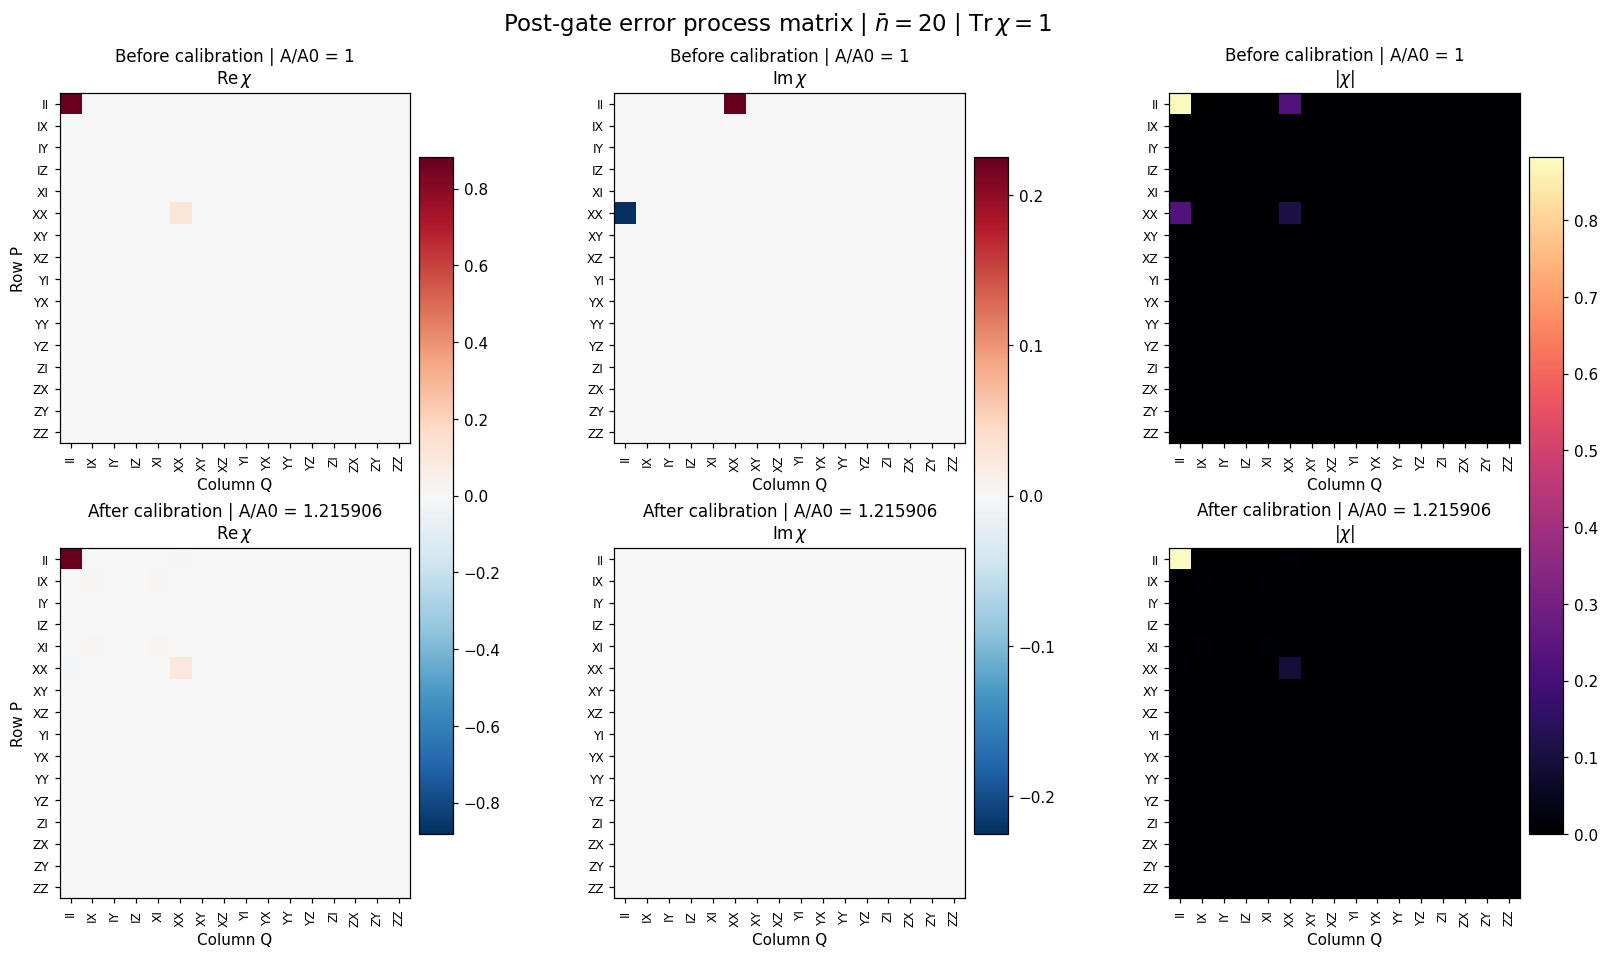

In [8]:
saved_figures = []

def plot_chi_panels(matrices, row_titles, title, mask_identity=False, matrix_symbol=r"\chi"):
    components = [(np.real, rf"$\mathrm{{Re}}\,{matrix_symbol}$", "RdBu_r"),
                  (np.imag, rf"$\mathrm{{Im}}\,{matrix_symbol}$", "RdBu_r"),
                  (np.abs, rf"$|{matrix_symbol}|$", "magma")]
    figure, axes = plt.subplots(
        len(matrices), 3, squeeze=False,
        figsize=(15, 4.3 * len(matrices)), constrained_layout=True,
    )
    for column, (transform, component_title, cmap_name) in enumerate(components):
        arrays = [np.ma.array(transform(chi), mask=np.zeros((16, 16), dtype=bool)) for chi in matrices]
        if mask_identity:
            for array in arrays:
                array.mask[ii_index, ii_index] = True
        limit = max(max(float(np.max(np.abs(array))) for array in arrays), 1e-12)
        norm = Normalize(vmin=0 if column == 2 else -limit, vmax=limit)
        cmap = plt.get_cmap(cmap_name).copy()
        cmap.set_bad("#c7c7c7")
        for row_index, (array, row_title) in enumerate(zip(arrays, row_titles)):
            axis = axes[row_index, column]
            im = axis.imshow(array, origin="upper", interpolation="nearest", cmap=cmap, norm=norm)
            axis.set_xticks(range(16), labels=pauli_labels, rotation=90, fontsize=8)
            axis.set_yticks(range(16), labels=pauli_labels, fontsize=8)
            axis.set_xlabel("Column Q")
            if column == 0:
                axis.set_ylabel("Row P")
            axis.set_title(f"{row_title}\n{component_title}", fontsize=11)
        colorbar = figure.colorbar(im, ax=axes[:, column].tolist(), shrink=0.84, pad=0.02)
        colorbar.formatter.set_powerlimits((-2, 2))
        colorbar.update_ticks()
    figure.suptitle(title, fontsize=15)
    return figure

def show_and_save(figure, n_bar, suffix):
    if SAVE_OUTPUTS:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        stem = str(float(n_bar)).replace(".", "p")
        path = OUTPUT_DIR / f"chi_{suffix}_nbar_{stem}.png"
        figure.savefig(path, dpi=180, bbox_inches="tight", facecolor="white")
        saved_figures.append(path)
    display(figure)
    plt.close(figure)

for n_bar, pair in comparisons.items():
    factor = float(summary.loc[(summary.n_bar == n_bar) & (summary.condition == "after"), "A_over_A0"].iloc[0])
    row_titles = ["Before calibration | A/A0 = 1", f"After calibration | A/A0 = {factor:.6f}"]
    figure = plot_chi_panels(
        [pair["before"], pair["after"]], row_titles,
        rf"Post-gate error process matrix | $\bar n={n_bar:g}$ | $\mathrm{{Tr}}\,\chi=1$",
    )
    show_and_save(figure, n_bar, "full_before_after")

## 微小な誤差要素の比較

$\chi_{II,II}$ が大きいため、同じ行列の **$(II,II)$ だけを灰色でマスク**して色スケールを
決め直します。マスクは表示にのみ適用され、行列の値は変更しません。
この図でも較正前後の色スケールは共通です。
保存値に含まれる微小な負の固有値など、数値計算上の残差も補正せず保持しています。
振幅に応じて自動選択された phonon cutoff は前後で少し異なる場合があり、
冒頭の表の `phonon_dim` に記録しています。

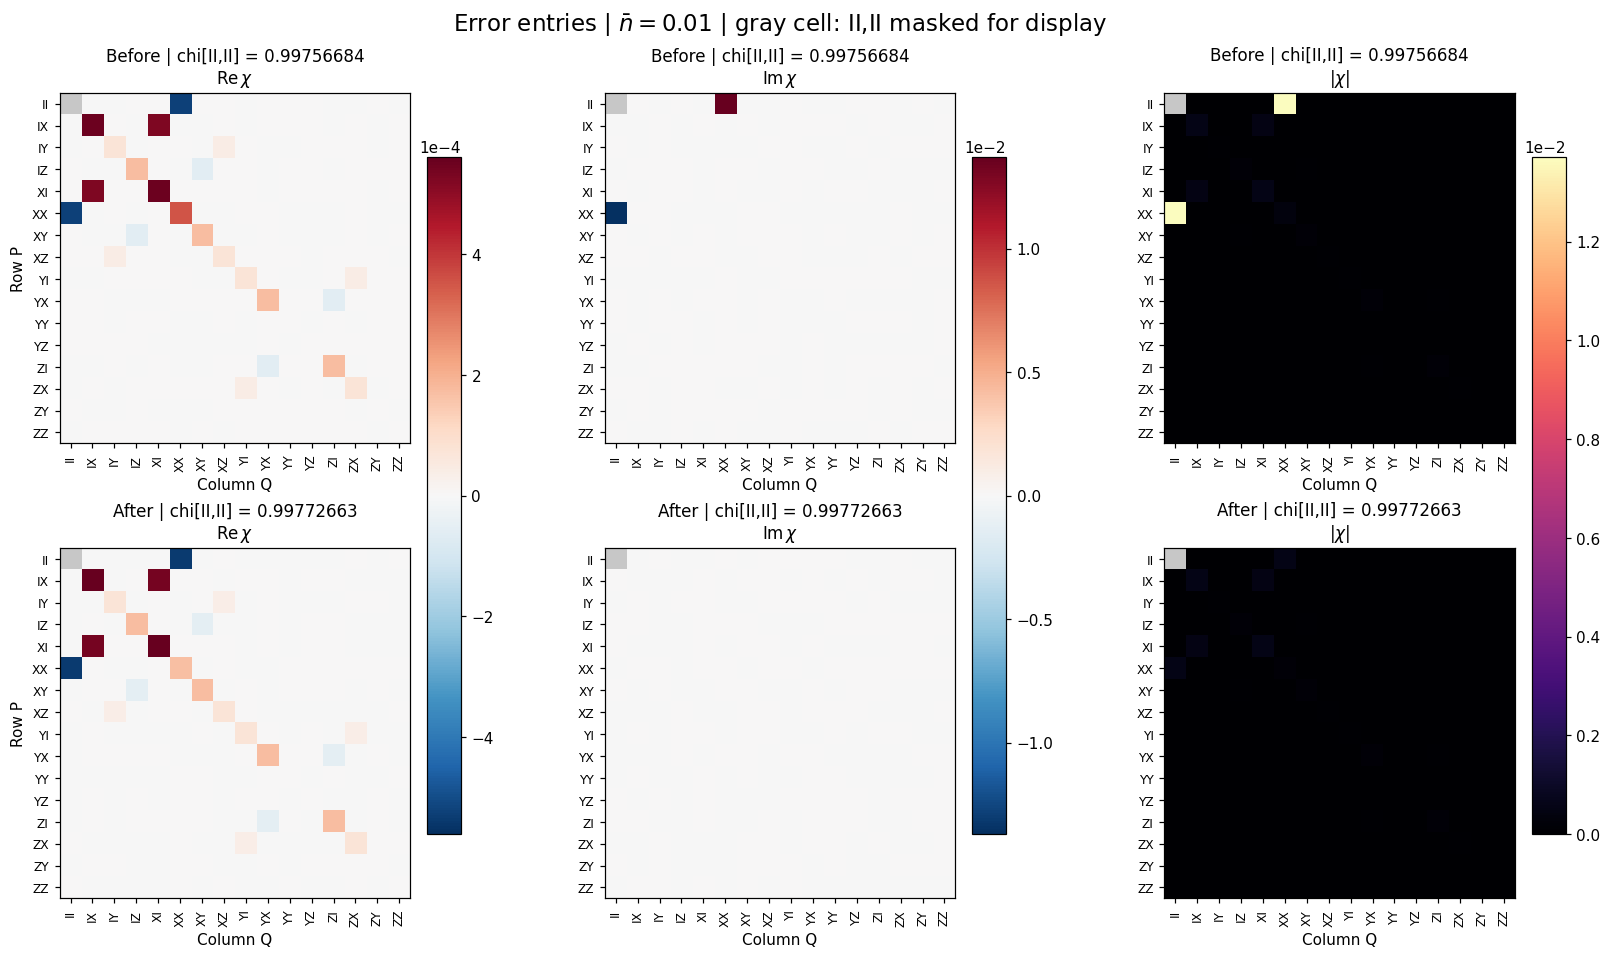

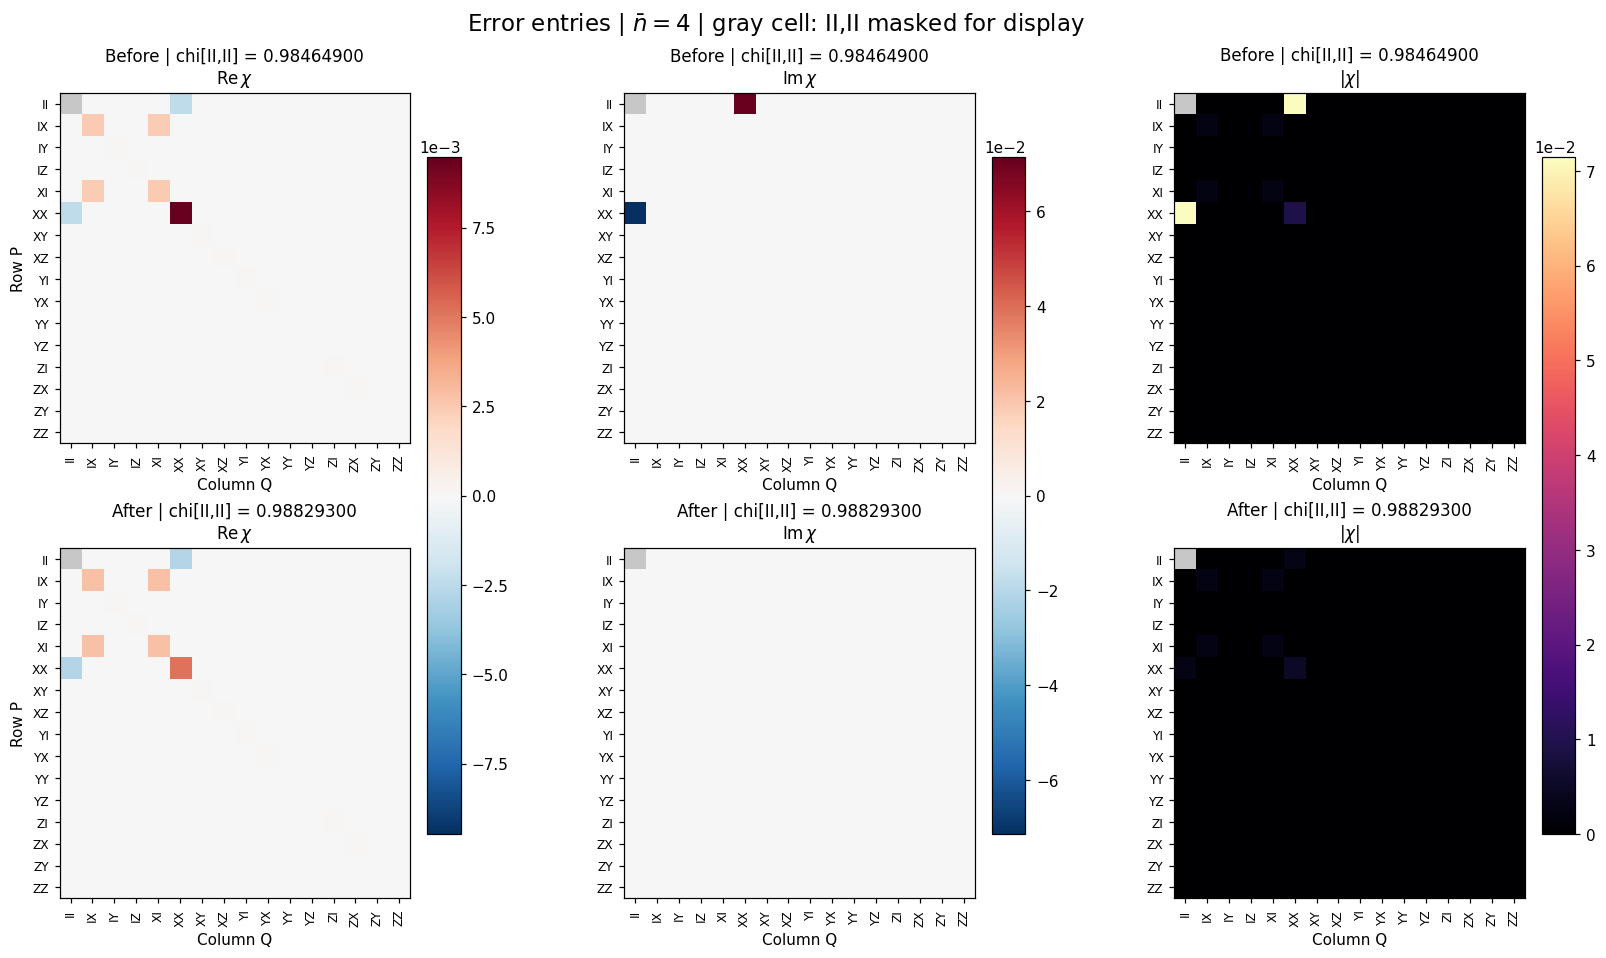

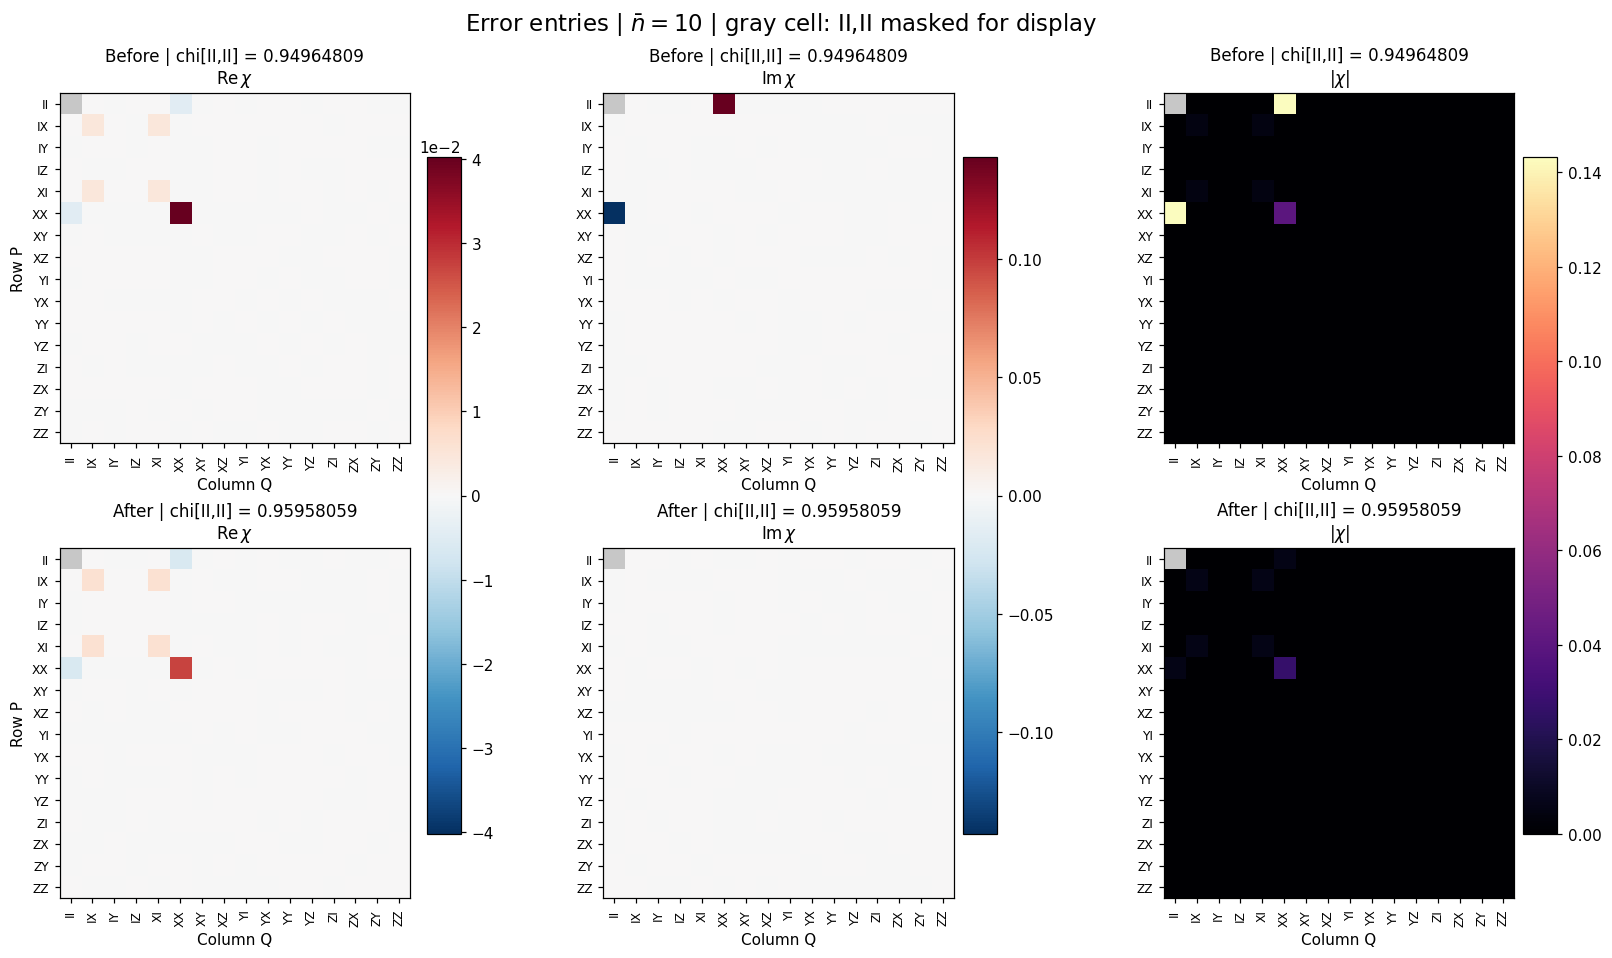

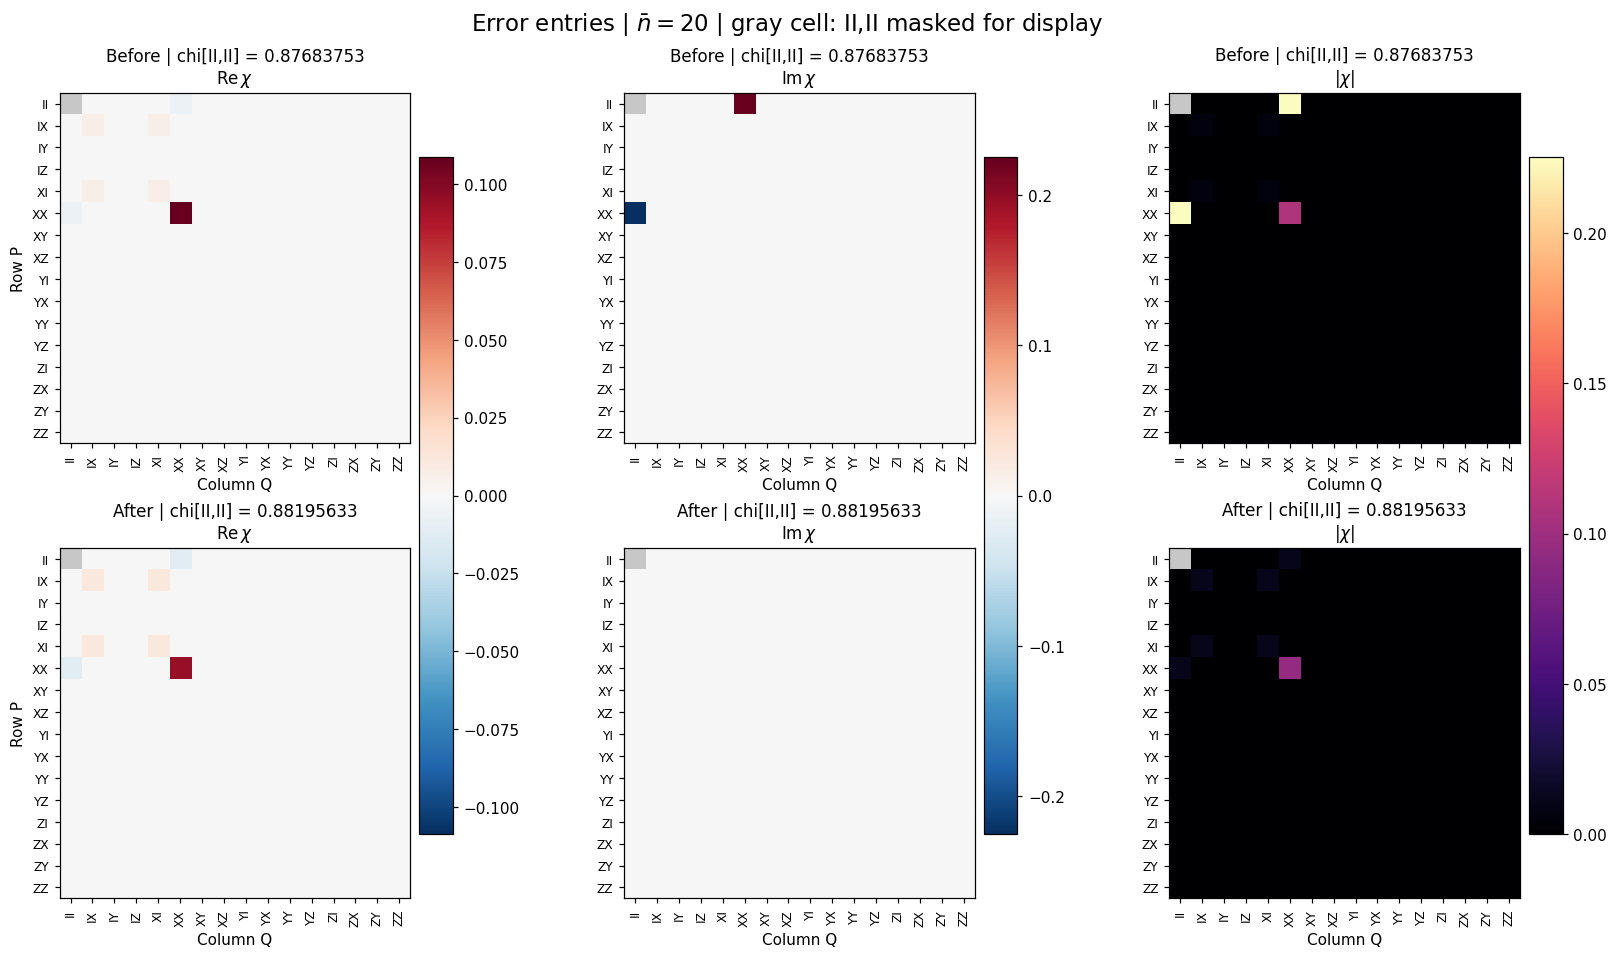

In [9]:
for n_bar, pair in comparisons.items():
    row_titles = [
        f"Before | chi[II,II] = {pair['before'][ii_index, ii_index].real:.8f}",
        f"After | chi[II,II] = {pair['after'][ii_index, ii_index].real:.8f}",
    ]
    figure = plot_chi_panels(
        [pair["before"], pair["after"]], row_titles,
        rf"Error entries | $\bar n={n_bar:g}$ | gray cell: II,II masked for display",
        mask_identity=True,
    )
    show_and_save(figure, n_bar, "error_entries_before_after")

## 較正による変化量

$\Delta\chi=\chi_{\rm after}-\chi_{\rm before}$ の実部・虚部・絶対値です。
全要素を含み、$\chi_{II,II}$ もマスクしません。右図は **複素差の絶対値**
$|\chi_{\rm after}-\chi_{\rm before}|$ であり、絶対値同士の差ではありません。
差分図の色スケールは差分の大きさから独立に決めます。

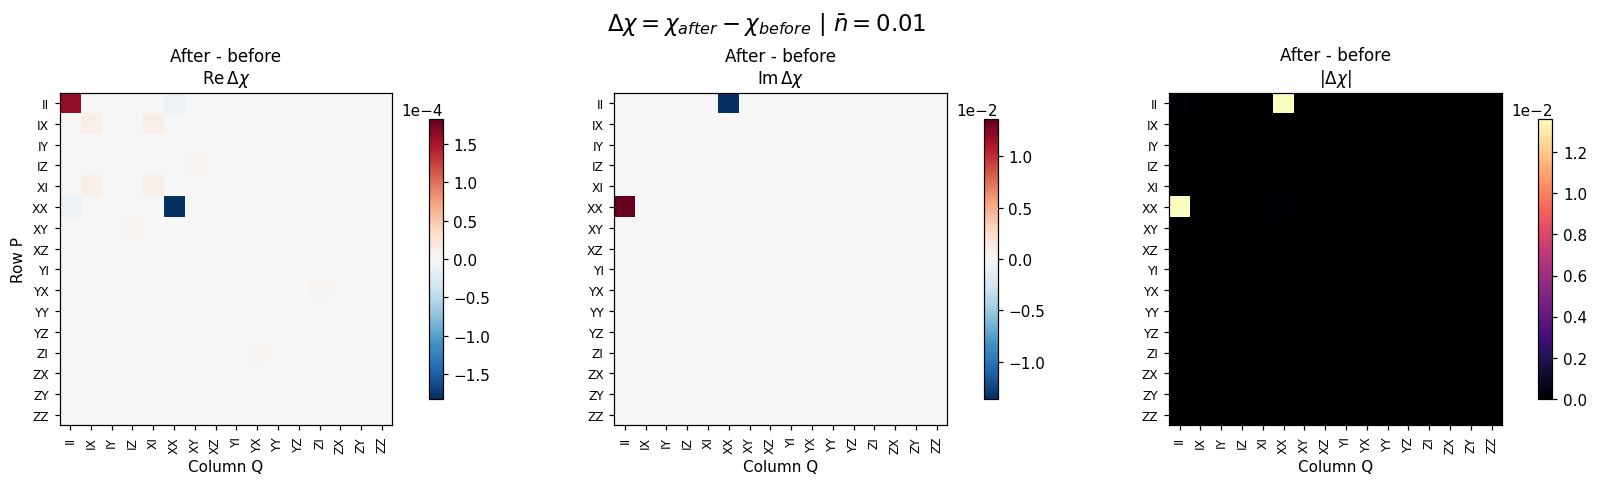

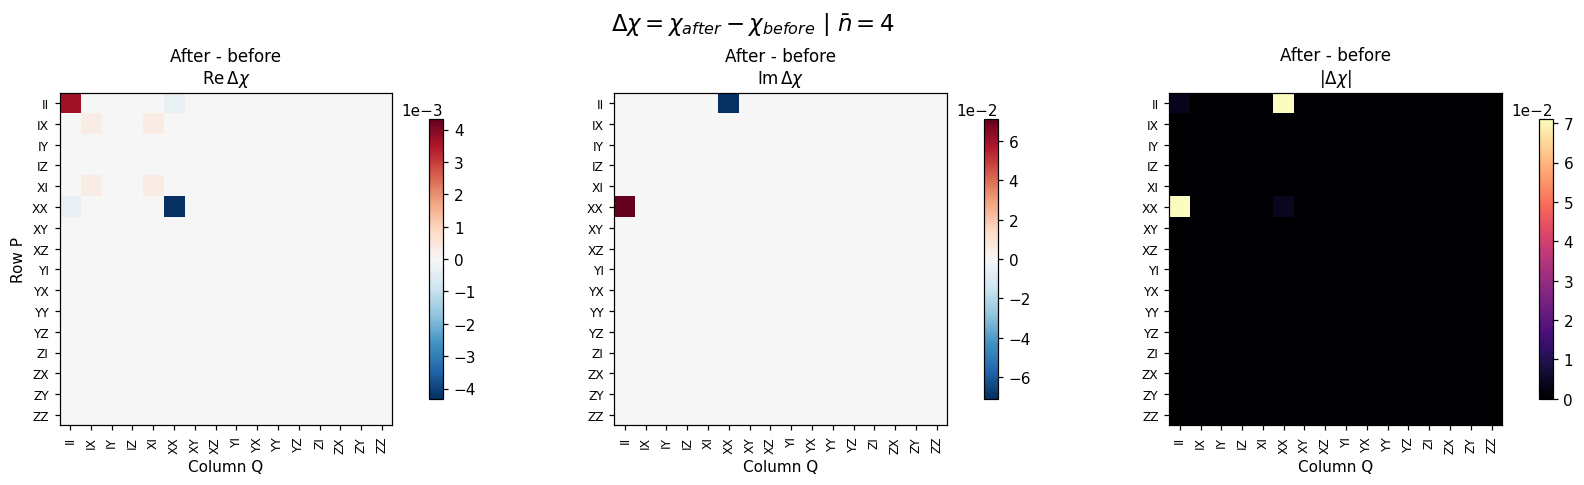

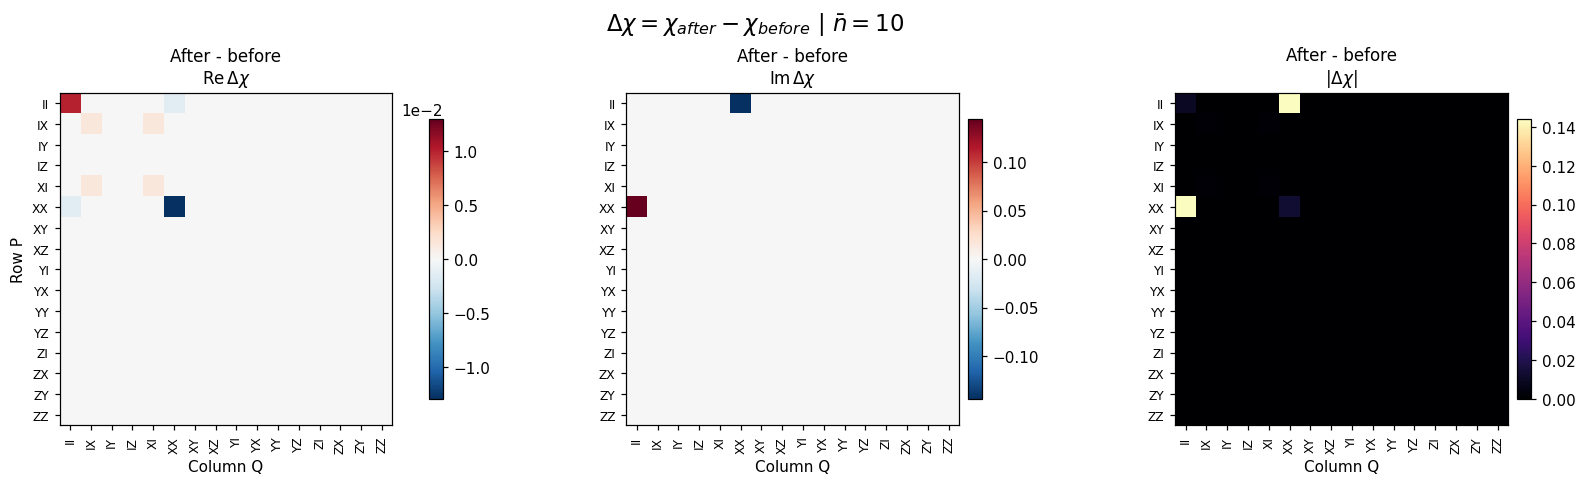

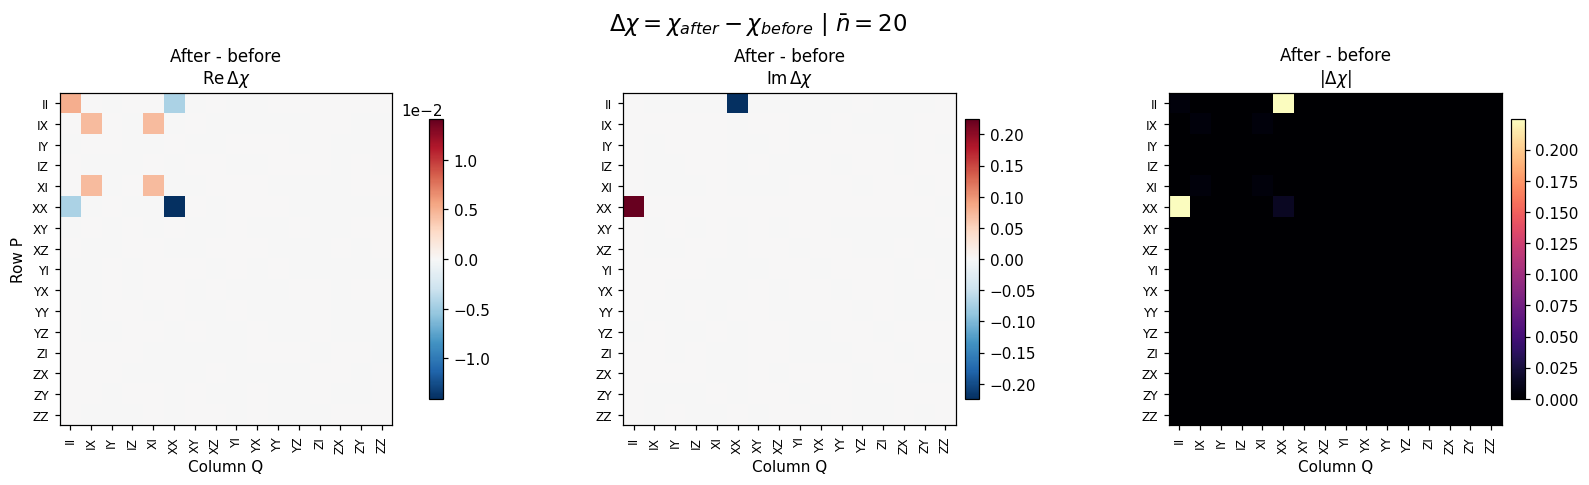

In [10]:
for n_bar, pair in comparisons.items():
    delta = pair["after"] - pair["before"]
    figure = plot_chi_panels(
        [delta], ["After - before"],
        rf"$\Delta\chi=\chi_{{after}}-\chi_{{before}}$ | $\bar n={n_bar:g}$",
        matrix_symbol=r"\Delta\chi",
    )
    show_and_save(figure, n_bar, "difference")

    if SHOW_NUMERIC_MATRICES:
        for label, matrix in [("Before", pair["before"]), ("After", pair["after"]), ("Difference", delta)]:
            display(Markdown(rf"**{label}, $\bar n={n_bar:g}$**"))
            table = pd.DataFrame(matrix, index=pauli_labels, columns=pauli_labels)
            table.index.name, table.columns.name = "P", "Q"
            display(table.style.format(lambda z: f"{z.real:.3e}{z.imag:+.3e}j"))

## 保存

`SAVE_OUTPUTS=True` の場合、図と選択条件の行列を
`results/drive_amplitude_chi_before_after/` に保存します。
`chi_before_after.npz` はマスクしていない複素行列で、配列の順序は `n_bar` に対応します。
`comparisons[n_bar]["before"]` / `["after"]` でも行列を取り出せます。

In [11]:
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    ordered_nbars = np.asarray(list(comparisons), dtype=float)
    before_stack = np.stack([comparisons[n]["before"] for n in ordered_nbars])
    after_stack = np.stack([comparisons[n]["after"] for n in ordered_nbars])
    np.savez_compressed(
        OUTPUT_DIR / "chi_before_after.npz",
        n_bar=ordered_nbars, pauli_labels=np.asarray(pauli_labels),
        convention="N_post = S_noisy @ inverse(S_ideal)",
        normalization="trace(chi) = 1; no CPTP projection",
        chi_before=before_stack, chi_after=after_stack,
        chi_difference=after_stack - before_stack,
    )
    summary.to_csv(OUTPUT_DIR / "chi_summary.csv", index=False)
    sources.to_csv(OUTPUT_DIR / "sources.csv", index=False)
    print(f"Saved to: {OUTPUT_DIR}")
    for path in saved_figures:
        print(path.name)
    print("chi_before_after.npz, chi_summary.csv, sources.csv")
else:
    print("表示のみ完了しました (SAVE_OUTPUTS=False)。")

Saved to: /Users/hirainoa/Desktop/量子/project/Moon_shot__高橋PJ/MS_gate_Hirai/results/drive_amplitude_chi_before_after
chi_full_before_after_nbar_0p01.png
chi_full_before_after_nbar_4p0.png
chi_full_before_after_nbar_10p0.png
chi_full_before_after_nbar_20p0.png
chi_error_entries_before_after_nbar_0p01.png
chi_error_entries_before_after_nbar_4p0.png
chi_error_entries_before_after_nbar_10p0.png
chi_error_entries_before_after_nbar_20p0.png
chi_difference_nbar_0p01.png
chi_difference_nbar_4p0.png
chi_difference_nbar_10p0.png
chi_difference_nbar_20p0.png
chi_before_after.npz, chi_summary.csv, sources.csv


保存済み n_bar: [0.01, 2.0, 4.0, 10.0, 20.0]


,condition,n_bar,A_peak,delta,gate_time_us,phonon_dim,scattering_scales_with_intensity,"Re chi[II,II]","Re chi[IX,XI]"
0,rectangular_A_infidelity,10.0,0.135232,0.5,100.0,170,True,0.961369,0.005591
1,pulse_sin2_calibrated,10.0,0.305063,1.0,100.0,171,True,0.966430,0.001981
2,pulse_blackman_calibrated,10.0,0.424495,1.5,100.0,171,True,0.967369,0.000974


,condition,source
0,rectangular_A_infidelity,results/chi_error_element_fit/advanced_publica...
1,pulse_sin2_calibrated,results/chi_error_element_fit/advanced_publica...
2,pulse_blackman_calibrated,results/chi_error_element_fit/advanced_publica...


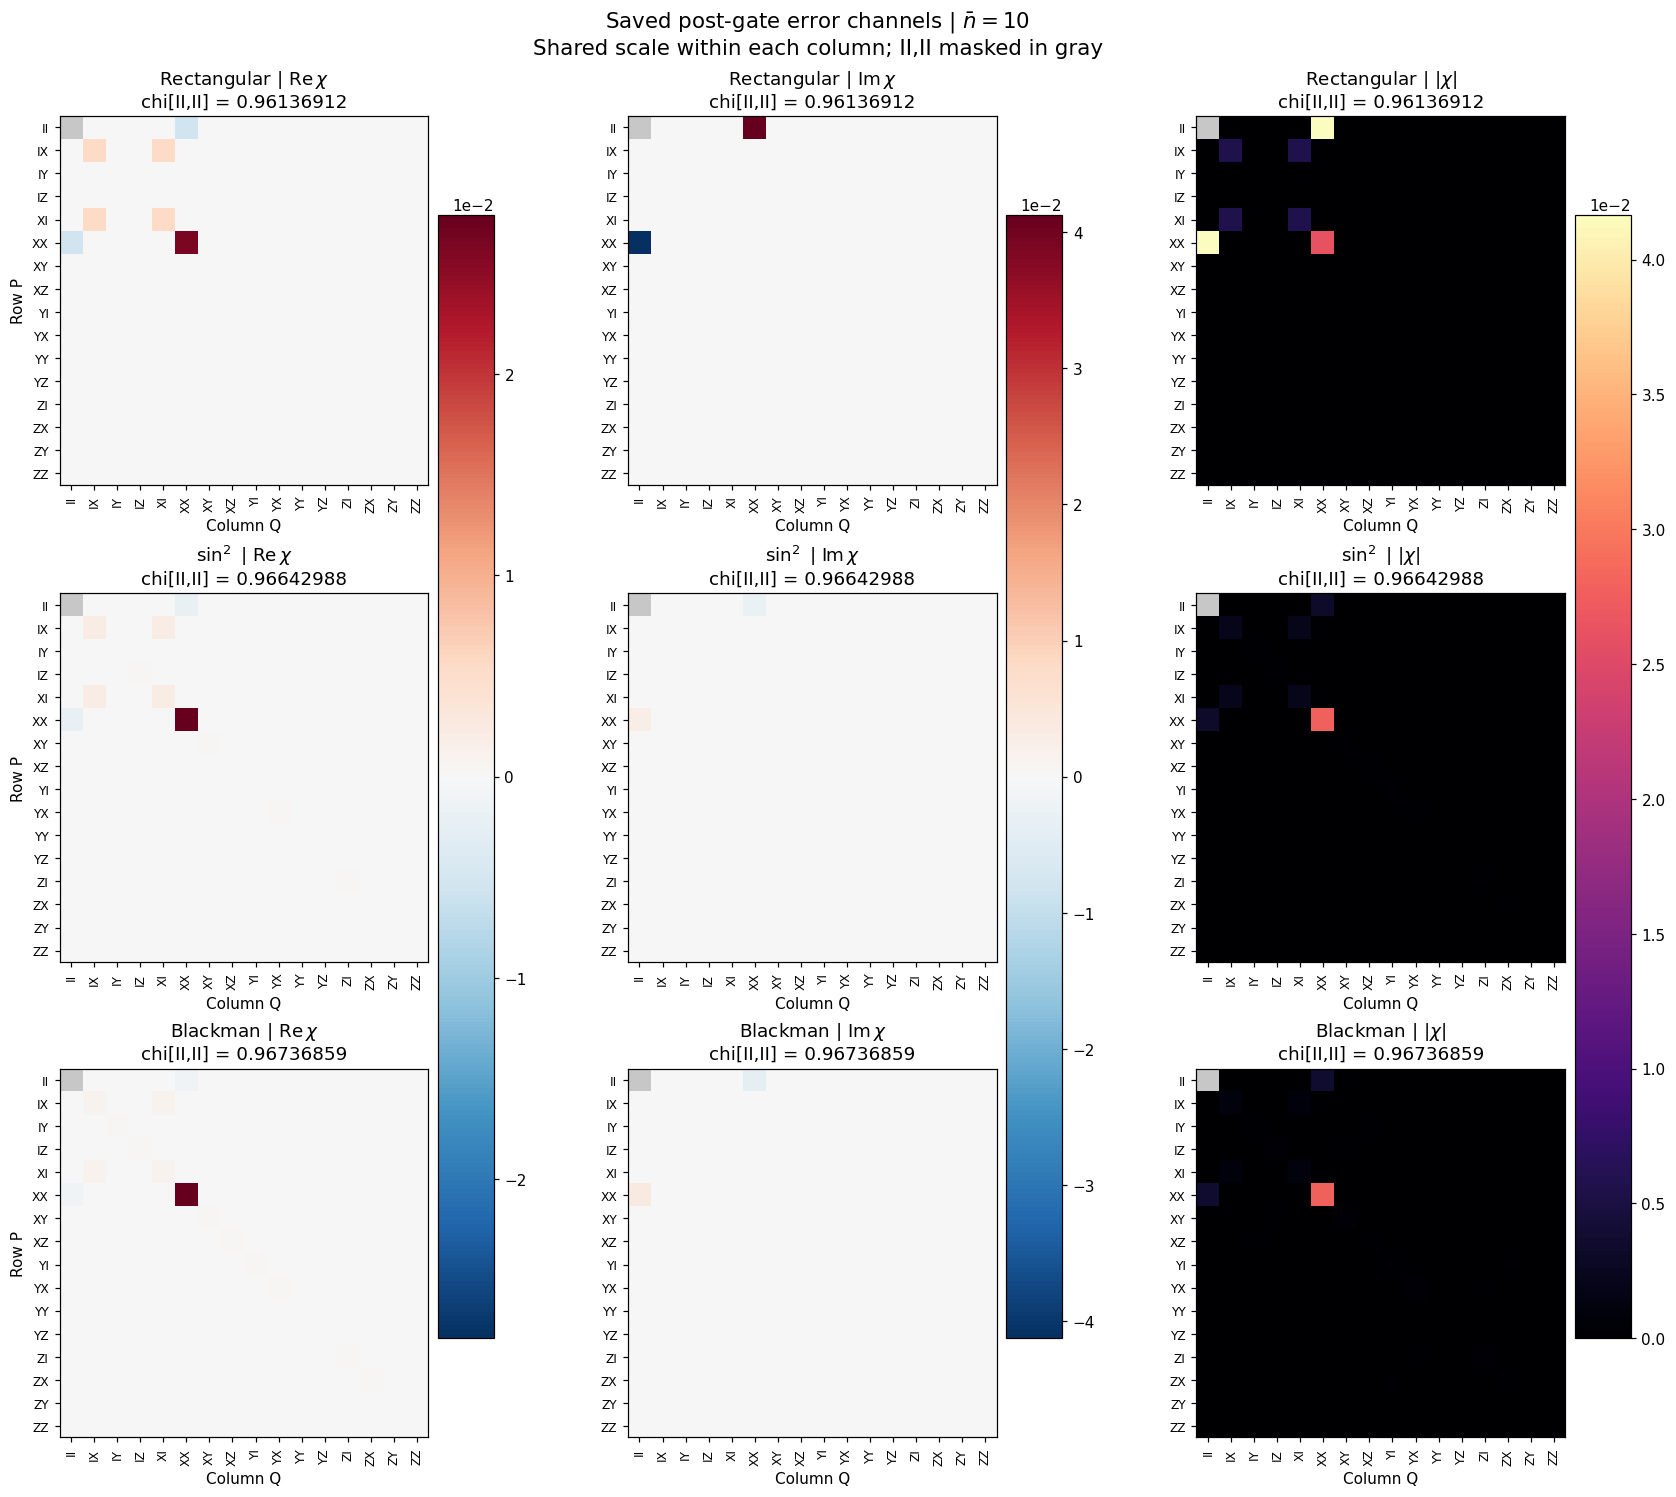

In [13]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
from IPython.display import display

# ---- 編集可能な表示条件（QPT・較正は再実行しない）----
SHAPED_PULSE_NBAR = float(globals().get("SELECTED_NBAR_FOR_CHI", 10.0))
SHAPED_PULSE_INCLUDE_RECTANGULAR = True
SHAPED_PULSE_MASK_IDENTITY = True  # II,II だけ灰色でマスク。元の行列は保持する。
SHAPED_PULSE_SAVE_OUTPUTS = False  # True: PNG・NPZ・条件表を保存


def display_cached_shaped_pulse_channels(
    n_bar, include_rectangular=True, mask_identity=True, save_outputs=False,
):
    current = Path.cwd().resolve()
    project_root = next(
        (path for path in (current, *current.parents)
         if (path / "chi_error_nbar_workflow.py").is_file()),
        None,
    )
    if project_root is None:
        raise FileNotFoundError("MS_gate_Hirai 内でこのセルを実行してください。")
    data_dir = project_root / "results" / "chi_error_element_fit"
    cache_dir = (
        data_dir / "advanced_publication_validation" / "physical_control_validation"
        / "fair_calibrated_comparison"
    )
    catalog = pd.read_csv(cache_dir / "fair_control_qpt_summary.csv")
    manifest = json.loads(
        (data_dir / "publication_reproducibility_manifest.json").read_text(encoding="utf-8")
    )
    if manifest["error_channel_convention"] != "undo_before_actual":
        raise ValueError("保存データが post-gate 誤差チャネルの規約と一致しません。")
    labels = list(manifest["pauli_basis_order"])
    if labels != [p + q for p in "IXYZ" for q in "IXYZ"]:
        raise ValueError("想定と異なる Pauli 基底順序です。")
    ii, ix, xi = (labels.index(label) for label in ("II", "IX", "XI"))
    conditions = [
        ("pulse_sin2_calibrated", r"$\sin^2$"),
        ("pulse_blackman_calibrated", "Blackman"),
    ]
    if include_rectangular:
        conditions.insert(0, ("rectangular_A_infidelity", "Rectangular"))
    available = sorted(set.intersection(*[
        set(catalog.loc[catalog["condition"] == condition, "n_bar"].astype(float))
        for condition, _ in conditions
    ]))
    n_bar = float(n_bar)
    if not np.isfinite(n_bar) or n_bar < 0:
        raise ValueError("SHAPED_PULSE_NBAR は有限な非負の値にしてください。")

    channels, rows, source_rows = {}, [], []
    for condition, title in conditions:
        selected = catalog.loc[
            (catalog["condition"] == condition)
            & np.isclose(catalog["n_bar"].astype(float), n_bar, rtol=0, atol=1e-10)
        ]
        if len(selected) != 1:
            raise ValueError(
                f"{condition}, n_bar={n_bar:g} のキャッシュを一意に選べません。"
                f"共通の保存済み n_bar: {available}"
            )
        row = selected.iloc[0]
        # CSV 内の過去の絶対パスに依存せず、現在のプロジェクトから読む。
        path = cache_dir / "qpt_cache" / Path(row["cache_path"]).name
        if not path.is_file():
            raise FileNotFoundError(f"保存済み QPT がありません: {path}")
        with np.load(path, allow_pickle=False) as payload:
            chi = np.asarray(payload["chi_trace_normalized"], dtype=complex).copy()
            metadata = json.loads(str(payload["metadata_json"].item()))
            if str(payload["condition"].item()) != condition:
                raise ValueError(f"キャッシュの条件名が一致しません: {path}")
            if not np.isclose(float(payload["n_bar"].item()), n_bar, rtol=0, atol=1e-10):
                raise ValueError(f"キャッシュの温度が一致しません: {path}")
            if "pauli_labels" in payload and payload["pauli_labels"].tolist() != labels:
                raise ValueError(f"キャッシュの Pauli 基底が一致しません: {path}")
        for key in ("n_bar", "amplitude_peak", "detuning", "t_gate_phys"):
            if not np.isclose(float(metadata[key]), float(row[key]), rtol=1e-10, atol=1e-12):
                raise ValueError(f"CSV とキャッシュの {key} が一致しません: {path}")
        for key in ("condition", "shape", "scattering_scales_with_intensity"):
            if str(metadata[key]).lower() != str(row[key]).lower():
                raise ValueError(f"CSV とキャッシュの {key} が一致しません: {path}")
        if chi.shape != (16, 16) or not np.isfinite(chi).all():
            raise ValueError(f"有限な 16 x 16 の chi 行列が必要です: {path}")
        if not np.isclose(np.trace(chi), 1.0, rtol=0, atol=1e-9):
            raise ValueError(f"trace-normalized な chi が必要です: {path}")
        if not np.allclose(chi, chi.conj().T, rtol=0, atol=1e-9):
            raise ValueError(f"chi の Hermiticity を確認してください: {path}")
        channels[condition] = chi
        rows.append({
            "condition": condition, "n_bar": n_bar,
            "A_peak": float(metadata["amplitude_peak"]),
            "delta": float(metadata["detuning"]),
            "gate_time_us": float(metadata["t_gate_phys"]) * 1e6,
            "phonon_dim": int(metadata["phonon_dim"]),
            "scattering_scales_with_intensity": metadata["scattering_scales_with_intensity"],
            "Re chi[II,II]": float(chi[ii, ii].real),
            "Re chi[IX,XI]": float(chi[ix, xi].real),
        })
        source_rows.append({"condition": condition, "source": str(path.relative_to(project_root))})

    summary, sources = pd.DataFrame(rows), pd.DataFrame(source_rows)
    print("保存済み n_bar:", available)
    display(summary)
    display(sources)
    figure, axes = plt.subplots(
        len(conditions), 3, squeeze=False,
        figsize=(15.5, 4.5 * len(conditions)), constrained_layout=True,
    )
    components = [
        (np.real, r"$\mathrm{Re}\,\chi$", "RdBu_r"),
        (np.imag, r"$\mathrm{Im}\,\chi$", "RdBu_r"),
        (np.abs, r"$|\chi|$", "magma"),
    ]
    for column, (component, component_title, cmap_name) in enumerate(components):
        arrays = [
            np.ma.array(component(channels[name]), mask=np.zeros((16, 16), dtype=bool))
            for name, _ in conditions
        ]
        if mask_identity:
            for array in arrays:
                array.mask[ii, ii] = True
        limit = max(max(float(np.max(np.abs(array))) for array in arrays), 1e-12)
        norm = Normalize(vmin=0 if column == 2 else -limit, vmax=limit)
        cmap = plt.get_cmap(cmap_name).copy()
        cmap.set_bad("#c7c7c7")
        for row_index, ((condition, title), array) in enumerate(zip(conditions, arrays)):
            axis = axes[row_index, column]
            im = axis.imshow(array, origin="upper", interpolation="nearest", cmap=cmap, norm=norm)
            axis.set_xticks(range(16), labels=labels, rotation=90, fontsize=8)
            axis.set_yticks(range(16), labels=labels, fontsize=8)
            axis.set_xlabel("Column Q")
            if column == 0:
                axis.set_ylabel("Row P")
            identity = channels[condition][ii, ii].real
            axis.set_title(f"{title} | {component_title}\nchi[II,II] = {identity:.8f}")
        colorbar = figure.colorbar(im, ax=axes[:, column].tolist(), shrink=0.85, pad=0.02)
        colorbar.formatter.set_powerlimits((-2, 2))
        colorbar.update_ticks()
    mask_note = "II,II masked in gray" if mask_identity else "all entries shown"
    figure.suptitle(
        rf"Saved post-gate error channels | $\bar n={n_bar:g}$"
        + "\n" + f"Shared scale within each column; {mask_note}",
        fontsize=14,
    )

    if save_outputs:
        output_dir = project_root / "results" / "calibration_channel_comparison" / "sin2_blackman_chi"
        output_dir.mkdir(parents=True, exist_ok=True)
        stem = f"shaped_pulse_chi_nbar_{str(n_bar).replace('.', 'p')}"
        figure.savefig(output_dir / f"{stem}.png", dpi=200, bbox_inches="tight")
        summary.to_csv(output_dir / f"{stem}_summary.csv", index=False)
        sources.to_csv(output_dir / f"{stem}_sources.csv", index=False)
        np.savez_compressed(
            output_dir / f"{stem}.npz",
            n_bar=n_bar, condition=np.asarray([name for name, _ in conditions]),
            pauli_labels=np.asarray(labels),
            convention="N_post = S_noisy @ inverse(S_ideal)",
            chi=np.stack([channels[name] for name, _ in conditions]),
        )
        print(f"Saved: {output_dir}")
    display(figure)
    plt.close(figure)
    return {"chi": channels, "summary": summary, "sources": sources, "pauli_labels": labels}


SHAPED_PULSE_RESULT = display_cached_shaped_pulse_channels(
    SHAPED_PULSE_NBAR,
    include_rectangular=SHAPED_PULSE_INCLUDE_RECTANGULAR,
    mask_identity=SHAPED_PULSE_MASK_IDENTITY,
    save_outputs=SHAPED_PULSE_SAVE_OUTPUTS,
)
